# Лабораторная работа 4. Базовые прогнозы и проверка качества

Цель — сравнить пять базовых моделей на горизонте одной недели, оценить интервалы прогноза и измерить эффект утечки. Данные имитируют ежедневный спрос с линейным ростом, недельным профилем и случайным шумом.

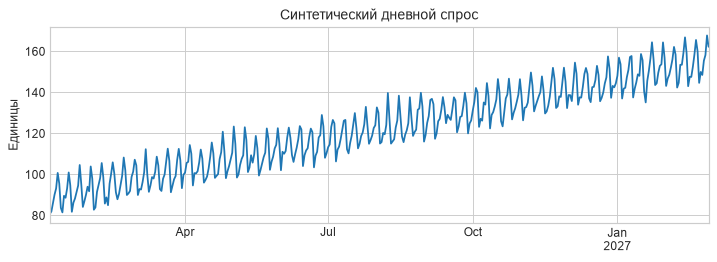

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.forecasting.theta import ThetaModel

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 85
rng = np.random.default_rng(404)
m = H = 7
t = np.arange(420)
weekday_effect = np.array([-5, -2, 0, 3, 7, 15, 9])
y = pd.Series(85 + 0.16 * t + weekday_effect[t % m] + rng.normal(0, 1.9, len(t)),
              index=pd.date_range("2026-01-05", periods=len(t), freq="D"),
              name="Спрос")
y.plot(figsize=(10, 3), title="Синтетический дневной спрос", ylabel="Единицы")
plt.show()

models = {
    "Naive": lambda train: np.repeat(train.iloc[-1], H),
    "Seasonal Naive": lambda train: np.resize(train.iloc[-m:].to_numpy(), H),
    "Mean": lambda train: np.repeat(train.mean(), H),
    "Drift": lambda train: train.iloc[-1] + np.arange(1, H + 1)
        * (train.iloc[-1] - train.iloc[0]) / (len(train) - 1),
    "Theta": lambda train: ThetaModel(train, period=m, deseasonalize=True,
                                      use_test=False, method="additive").fit().forecast(H).to_numpy(),
}

Десять неперекрывающихся тестовых недель одинаковы в обеих схемах. Expanding использует всю доступную историю, sliding — последние 28 дней. Для каждого фолда MASE масштабируется средней абсолютной ошибкой сезонной разности на его обучающем отрезке. При одинаковом масштабе внутри фолда MASE и MAE ранжируют модели одинаково. Между фолдами масштаб может меняться.

In [2]:
origins = np.arange(len(y) - 10 * H, len(y), H)
records = []
for scheme, window in (("Expanding", None), ("Sliding (28 дней)", 28)):
    for origin in origins:
        start = 0 if window is None else origin - window
        train = y.iloc[start:origin]
        test = y.iloc[origin:origin + H]
        assert train.index.max() < test.index.min()
        scale = train.diff(m).abs().dropna().mean()
        actual = test.to_numpy()
        for name, model in models.items():
            forecast = model(train)
            ae = np.abs(actual - forecast)
            for h in range(H):
                records.append({
                    "Схема": scheme, "Модель": name, "Фолд": origin, "h": h + 1,
                    "MAE": ae[h], "MSE": ae[h] ** 2,
                    "MAPE %": 100 * ae[h] / abs(actual[h]),
                    "sMAPE %": 200 * ae[h] / (abs(actual[h]) + abs(forecast[h])),
                    "MASE": ae[h] / scale,
                })
point = pd.DataFrame(records)
table = point.groupby(["Схема", "Модель"])[["MAE", "MSE", "MAPE %", "sMAPE %", "MASE"]].mean()
table.insert(1, "RMSE", np.sqrt(table.pop("MSE")))
display(table.sort_values(["Схема", "MASE"]).round(3))
fold_mae = point.groupby(["Схема", "Модель", "Фолд"])["MAE"].mean()
ranking = pd.DataFrame({metric: table.groupby(level=0)[metric].idxmin().map(lambda key: key[1])
                        for metric in ("MASE", "MAE", "RMSE")})
instability = fold_mae.groupby(level=[0, 1]).std()
display(ranking)
display(instability.unstack(0).round(3).rename_axis("SD недельных MAE"))

MAE    RMSE  MAPE %  sMAPE %    MASE
Схема             Модель                                                 
Expanding         Theta            1.592   2.146   1.058    1.059   0.696
                  Seasonal Naive   2.241   2.931   1.492    1.503   0.979
                  Naive            7.642   9.255   5.230    5.059   3.337
                  Drift            7.776   9.461   5.334    5.145   3.396
                  Mean            31.221  32.134  20.546   23.007  13.624
Sliding (28 дней) Theta            1.906   2.514   1.271    1.273   0.871
                  Seasonal Naive   2.241   2.931   1.492    1.503   1.010
                  Mean             6.630   7.954   4.333    4.407   2.961
                  Naive            7.642   9.255   5.230    5.059   3.432
                  Drift            8.881  10.335   6.083    5.842   3.987

,MASE,MAE,RMSE
Схема,,,
Expanding,Theta,Theta,Theta
Sliding (28 дней),Theta,Theta,Theta


Схема,Expanding,Sliding (28 дней)
SD недельных MAE,,
Drift,1.236,1.587
Mean,1.914,0.918
Naive,1.114,1.114
Seasonal Naive,0.759,0.759
Theta,0.674,0.717


## Интервалы Seasonal Naive

На 30 отдельных исторических неделях собираем знаковые ошибки «факт минус прогноз». Для каждого горизонта прибавляем к точечному прогнозу эмпирические квантили ошибок 0,05 и 0,95. Проверяем покрытие и ширину на десяти следующих неделях.

,Покрытие,Ширина
"Горизонт, день",,
1,1.0,10.450
2,0.8,11.361
3,0.7,6.449
4,1.0,9.196
5,0.7,7.131
6,0.9,8.064
7,1.0,7.890


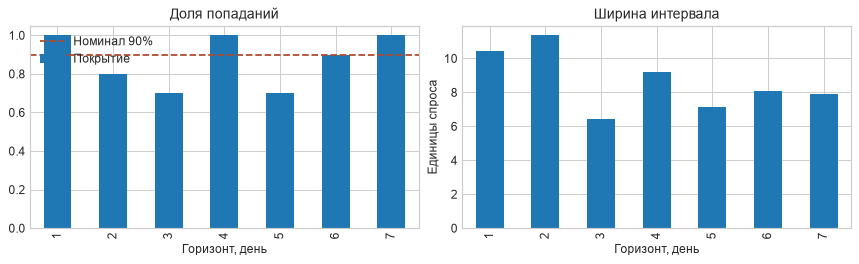

Общее покрытие: 87.1%, средняя ширина: 8.65.


In [3]:
def weekly_errors(origin):
    return y.iloc[origin:origin + H].to_numpy() - models["Seasonal Naive"](y.iloc[:origin])

calibration_origins = np.arange(origins[0] - 30 * H, origins[0], H)
assert calibration_origins[-1] + H <= origins[0]
calibration = np.array([weekly_errors(origin) for origin in calibration_origins])
test_errors = np.array([weekly_errors(origin) for origin in origins])
lower, upper = np.quantile(calibration, [0.05, 0.95], axis=0)
intervals = pd.DataFrame({
    "Покрытие": ((test_errors >= lower) & (test_errors <= upper)).mean(axis=0),
    "Ширина": upper - lower,
}, index=pd.Index(np.arange(1, H + 1), name="Горизонт, день"))
display(intervals.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
intervals["Покрытие"].plot.bar(ax=axes[0], ylim=(0, 1.05), title="Доля попаданий")
axes[0].axhline(0.9, ls="--", color="#ae492f", label="Номинал 90%")
axes[0].legend()
intervals["Ширина"].plot.bar(ax=axes[1], title="Ширина интервала", ylabel="Единицы спроса")
plt.show()
print(f"Общее покрытие: {intervals['Покрытие'].mean():.1%}, "
      f"средняя ширина: {intervals['Ширина'].mean():.2f}.")

## Эксперимент с утечкой

Для наглядности используем один и тот же алгоритм ближайшего сезонного соседа на одинаковых тестовых датах. Для случайного разбиения ближайший сосед того же дня недели может находиться в будущем. Отдельный учебный ряд с резкими недельными сдвигами показывает, почему такие соседи занижают ошибку. При честной оценке для всех семи прогнозов запрещены наблюдения начиная с даты выпуска прогноза.

In [4]:
leak_rng = np.random.default_rng(405)
# Уровень меняется между четырёхнедельными блоками.
block_levels = leak_rng.normal(0, 20, int(np.ceil(len(y) / 28)))
demo = 100 + weekday_effect[t % m] + block_levels[t // 28] + leak_rng.normal(0, 1, len(t))
shuffled = leak_rng.permutation(len(demo))
random_train = np.sort(shuffled[:int(0.8 * len(demo))])
random_test = np.sort(shuffled[int(0.8 * len(demo)):])
demo_origins = (random_test // H) * H
valid = demo_origins >= 2 * H
random_test, demo_origins = random_test[valid], demo_origins[valid]

def seasonal_neighbor(target, origin, chronological):
    candidates = random_train[random_train % m == target % m]
    if chronological:
        candidates = candidates[candidates < origin]
    if not len(candidates):
        return None
    return candidates[np.argmin(np.abs(candidates - target))]

pairs = []
for target, origin in zip(random_test, demo_origins):
    honest = seasonal_neighbor(target, origin, True)
    leaked = seasonal_neighbor(target, origin, False)
    if honest is not None and leaked is not None:
        pairs.append((target, honest, leaked))
target, honest, leaked = np.array(pairs).T
assert np.all(honest < (target // H) * H)
honest_mae = np.abs(demo[target] - demo[honest]).mean()
leaked_mae = np.abs(demo[target] - demo[leaked]).mean()
print(f"Одинаковых тестовых дат: {len(target)}")
print(f"Доля прогнозов со значениями из будущего: {(leaked > target).mean():.1%}")
print(f"Хронологическая MAE: {honest_mae:.2f}")
print(f"MAE со случайным split: {leaked_mae:.2f}")
print(f"Изменение MAE при утечке: {(leaked_mae / honest_mae - 1):+.1%}")

Одинаковых тестовых дат: 83
Доля прогнозов со значениями из будущего: 13.3%
Хронологическая MAE: 10.46
MAE со случайным split: 9.77
Изменение MAE при утечке: -6.6%


### Выводы

- Theta выиграл по MASE, MAE и RMSE в обеих схемах. Расширяющееся окно принесло ему меньшую MAE (1,592 против 1,906) и немного меньший разброс недельной MAE (0,674 против 0,717). Для этого ряда выбираем Theta и расширяющееся окно. Для ежедневного спроса MAE легко перевести в число единиц недопоставки или излишка при одинаковой цене этих ошибок. RMSE сильнее учитывает редкие большие ошибки. MASE показывает результат относительно сезонного масштаба.
- Разброс недельной MAE описывает стабильность оценки на выбранных фолдах. Sliding может быстрее реагировать на смену уровня, а expanding использует больше данных и подходит при стабильной структуре.
- Общее покрытие составило 87,1% при номинале 90%, средняя ширина — 8,65 единицы. На горизонтах 3 и 5 дней покрытие было 70%. По десяти наблюдениям на горизонт возможны только шаги по 10 п. п., поэтому оценки покрытия шумные. Ширина нужна, чтобы отличить полезный интервал от чрезмерно широкого.
- Случайное разбиение использовало будущие значения для 13,3% прогнозов и занизило MAE на 6,6% (9,77 против 10,46). Разницу MAE в диагностическом опыте нельзя считать ожидаемым улучшением прогноза при внедрении.